# 4. The NASA almond
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sap6/MFS/blob/main/notebooks/4_almond.ipynb)

**Notebooks:** [1. Sphere](1_sphere.ipynb) · [2. Torus](2_torus.ipynb) · [3. Cube & tetrahedron](3_cube.ipynb) · **4. NASA almond**

The NASA almond ($L = 0.2524\,\mathrm{m}$) is a standard radar-scattering benchmark (Section 6 of the paper). Every cross-section is a $3{:}1$ ellipse, so the continued field is singular near a *focal curve* at $94.3\%$ of the half-width in the mid-plane $z = 0$, and at the sharp conical tip this focal curve touches the boundary. Our layout places rows of electric and magnetic dipoles on $z = 0$ clustering towards the focal curve, continued across the last $1\,\mathrm{mm}$ at the tip by a singular tail with the elliptic-cone exponents of Table A.1 (`mfs/almond.py`).

In [1]:
# Set up paths (and get the code and the data when run on Colab)
import os, subprocess, sys
if "google.colab" in sys.modules:
    if not os.path.exists("/content/MFS"):
        subprocess.run(["git", "clone", "-q", "https://github.com/sap6/MFS", "/content/MFS"], check=True)
    os.chdir("/content/MFS/notebooks")            # numpy, scipy, numba and matplotlib come with Colab
elif os.path.isdir("notebooks") and os.path.isdir("mfs"):
    os.chdir("notebooks")
if os.path.abspath("..") not in sys.path:
    sys.path.insert(0, os.path.abspath(".."))

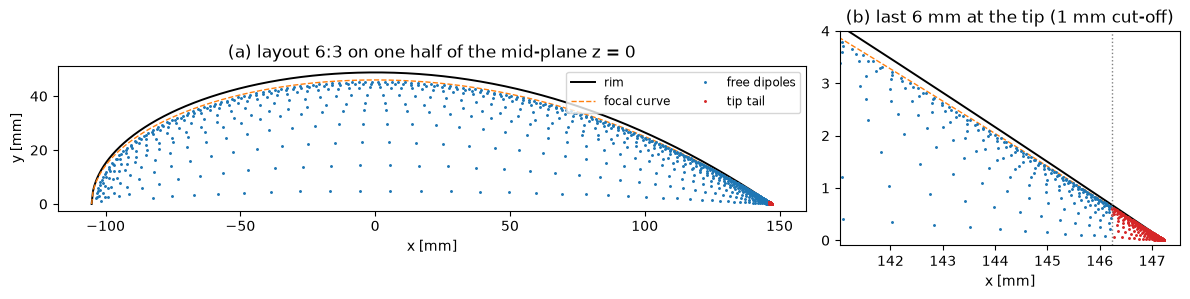

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from mfs import almond, core

y, (tail, row, r) = almond.source_rows(6, 3)    # layout 6:3: six inner rows + four rows clustering towards the focal curve
xs = np.linspace(almond.T0 * almond.L, almond.T1 * almond.L, 500)
rim = almond.semi_axes(xs)[0]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.2), gridspec_kw={"width_ratios": [2.2, 1]})
for ax in (ax1, ax2):
    ax.plot(xs * 1e3, rim * 1e3, "k-", lw=1.4, label="rim")
    ax.plot(xs * 1e3, almond.ETA_F * rim * 1e3, "--", color="tab:orange", lw=1.0, label="focal curve")
    ax.plot(y[:, 0] * 1e3, y[:, 1] * 1e3, ".", color="tab:blue", ms=2.2, label="free dipoles")
    ax.plot(tail[:, 0] * 1e3, tail[:, 1] * 1e3, ".", color="tab:red", ms=2.2, label="tip tail")
    ax.set_aspect("equal")
ax1.set(xlabel="x [mm]", ylabel="y [mm]", title="(a) layout 6:3 on one half of the mid-plane z = 0")
ax1.legend(fontsize=8.5, loc="upper right", ncol=2)
tip_mm = almond.T1 * almond.L * 1e3
ax2.axvline(tip_mm - 1.0, ls=":", color="grey", lw=1.0)
ax2.set(xlim=(tip_mm - 6.2, tip_mm + 0.3), ylim=(-0.1, 4.0), xlabel="x [mm]", title="(b) last 6 mm at the tip (1 mm cut-off)")
fig.tight_layout()
plt.show()

## Nose-on convergence at 1.19 GHz
At $1.19\,\mathrm{GHz}$ the almond is one wavelength long. A nose-on wave polarised along $y$ excites one of the four mirror-symmetry classes ($(s_y, s_z) = (-1, +1)$). Each layout is compared against the finest layout, $8{:}5$.

In [3]:
k = 2 * np.pi * 1.19e9 / almond.C0
pts = 0.3 * core.fibonacci(400)
E_ref = almond.nose_on(k, 8, 5, pts)[2]
for n_mid, n_F in ((3, 0), (4, 1), (5, 2), (6, 3)):
    src, c, E, shape = almond.nose_on(k, n_mid, n_F, pts)
    ext, sca = almond.optical(k, src, c)
    print(f"layout {n_mid}:{n_F}, {shape[1]} solved unknowns: difference {core.rel(E, E_ref):.1e}, "
          f"optical mismatch {abs(ext - sca) / sca:.1e}")

layout 3:0, 815 solved unknowns: difference 6.7e-02, optical mismatch 1.4e-01


layout 4:1, 1407 solved unknowns: difference 4.0e-03, optical mismatch 8.2e-03


layout 5:2, 2143 solved unknowns: difference 2.8e-04, optical mismatch 4.1e-04


layout 6:3, 2987 solved unknowns: difference 5.6e-05, optical mismatch 8.6e-06


## Monostatic radar cross-section against the Austin benchmark
At $3.5\,\mathrm{GHz}$ ($361$ look angles at $0.5^\circ$ spacing for both HH and VV polarisations), one Cholesky factorisation per symmetry class serves every look angle (`~3 minutes` on 2 cores). Plotting the full $0.5^\circ$ reference curve from the Austin RCS Benchmark Suite (Kelley et al., 2020) resolves the sharp interference nulls and reproduces the $0.043\,\mathrm{dB}$ (HH) and $0.011\,\mathrm{dB}$ (VV) mean differences of Table 3.

3.5 GHz HH: mean |MFS - Austin reference| = 0.043 dB
3.5 GHz VV: mean |MFS - Austin reference| = 0.011 dB


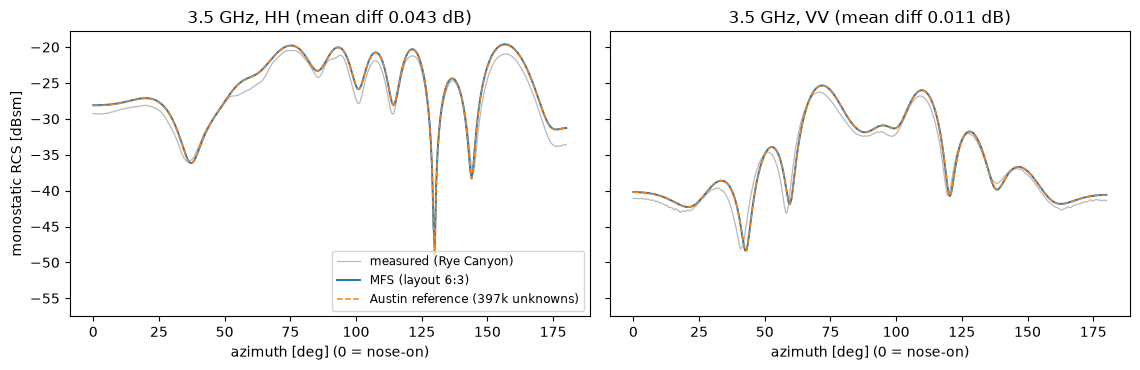

In [4]:
out = almond.rcs(3.5, step=0.5)            # 361 look angles, HH and VV (~3 minutes on 2 cores)

def austin(kind, pol):
    d = np.loadtxt(f"../data/austin_almond/{kind}_rcs.III.A.s1.fx1.{pol[0]}.txt")
    return d[:, 2], d[:, 3]

fig, axs = plt.subplots(1, 2, figsize=(11.5, 3.8), sharey=True)
for ax, pol in zip(axs, ("HH", "VV")):
    phi_m, meas = austin("meas.m1", pol)
    phi_r, ref_db = austin("ref", pol)
    mfs_db = 10 * np.log10(out["sigma_" + pol])
    th = ref_db.max() - 80.0
    mad = np.mean(np.abs(np.maximum(mfs_db, th) - np.maximum(ref_db, th)))
    print(f"3.5 GHz {pol}: mean |MFS - Austin reference| = {mad:.3f} dB")
    ax.plot(phi_m, meas, color="0.72", lw=0.9, label="measured (Rye Canyon)")
    ax.plot(out["phi_deg"], mfs_db, color="tab:blue", lw=1.4, label="MFS (layout 6:3)")
    ax.plot(phi_r, ref_db, "--", color="tab:orange", lw=1.1, label="Austin reference (397k unknowns)")
    ax.set(xlabel="azimuth [deg] (0 = nose-on)", title=f"3.5 GHz, {pol} (mean diff {mad:.3f} dB)")
axs[0].set_ylabel("monostatic RCS [dBsm]")
axs[0].legend(fontsize=8.5, loc="lower right")
fig.tight_layout()
plt.show()